In [ ]:
import pandas

data = pandas.read_csv("City_of_Pittsburgh_Public_Art.tsv", sep="\t")
#print(data.head(2))

cleanData = data.dropna(subset="neighborhood")
#print(cleanData.head(2))

scores = cleanData.groupby("neighborhood").agg(
    artCount=("id", "count"),
    artDiversity=("art_type", "nunique"),
    artistCount=("artist_name", "nunique")
)
#print(scores)

scores["quantityScore"] = scores["artCount"].rank(pct=True) * 100

scores["diversityScore"] = scores["artDiversity"].rank(pct=True) * 100

scores["artistScore"] = scores["artistCount"].rank(pct=True) * 100

scores["artFinalScore"] = (
    scores["quantityScore"] * 0.50 +
    scores["diversityScore"] * 0.30 +
    scores["artistScore"] * 0.20
)

scores = scores.sort_values(
    by="artFinalScore",
    ascending=False
)

#print(scores.head(15))

bestNeighborhoodByArt = scores.index[0]

print("Best neighborhood:", bestNeighborhoodByArt)
print("Score:", round(scores.iloc[0]["artFinalScore"], 2))

# scores.to_csv("../finalMetric/finalScoresArt.csv")

Best neighborhood: Central Business District
Score: 100.0


Link to dataset https://data.wprdc.org/dataset/city-of-pittsburgh-public-art/resource/00d74e83-8a23-486e-841b-286e1332a151

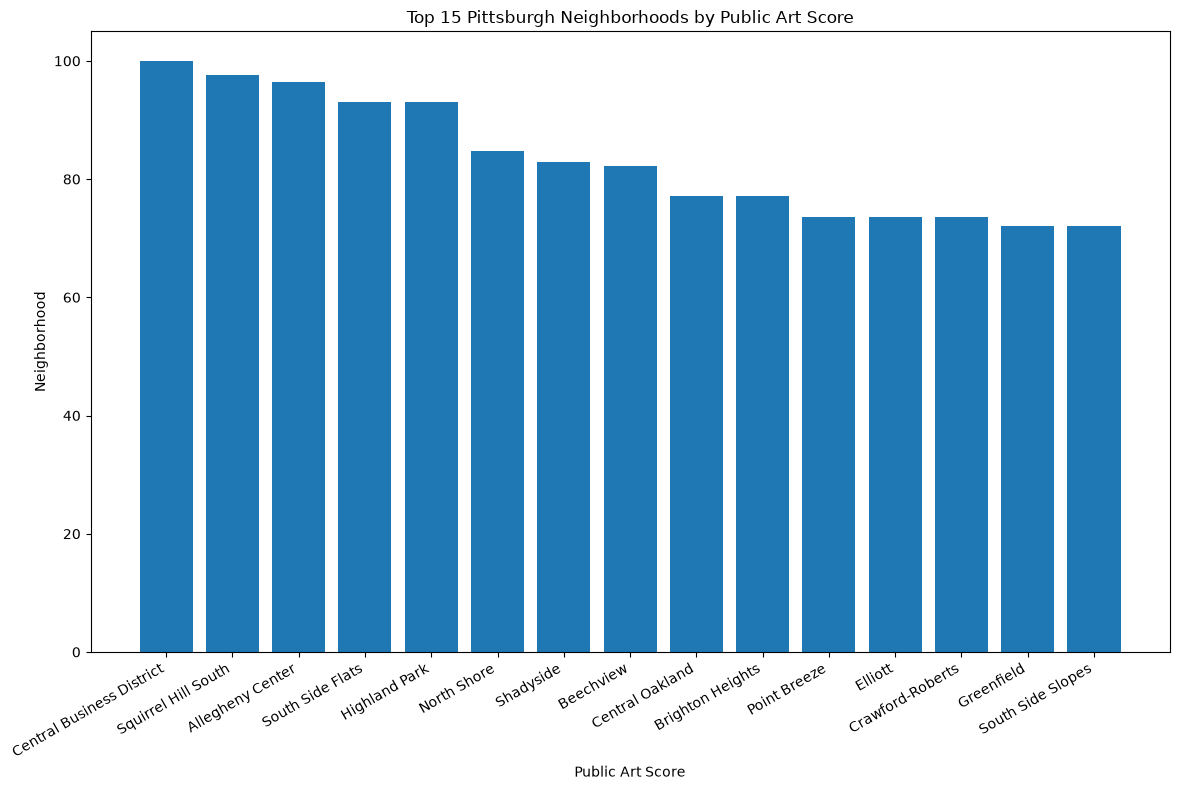

In [4]:
import matplotlib.pyplot as plt
from pandas import read_csv

finalScores = read_csv("../finalMetric/finalScoresArt.csv", index_col="neighborhood")

artGraph = finalScores.sort_values(
    by="artFinalScore",
    ascending=False
).head(15)

artGraph = artGraph.reset_index()

plt.figure(figsize=(12, 8))

plt.bar(
    artGraph["neighborhood"],
    artGraph["artFinalScore"]
)

plt.xlabel("Public Art Score")
plt.ylabel("Neighborhood")
plt.title("Top 15 Pittsburgh Neighborhoods by Public Art Score")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()